<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDS0321ENSkillsNetwork26802033-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **SpaceX  Falcon 9 First Stage Landing Prediction**


## Assignment: Exploring and Preparing Data


Estimated time needed: **70** minutes


In this assignment, we will predict if the Falcon 9 first stage will land successfully. SpaceX advertises Falcon 9 rocket launches on its website with a cost of 62 million dollars; other providers cost upward of 165 million dollars each, much of the savings is due to the fact that SpaceX can reuse the first stage.

In this lab, you will perform Exploratory Data Analysis and Feature Engineering.


Falcon 9 first stage will land successfully


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/landing_1.gif)


Several examples of an unsuccessful landing are shown here:


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/crash.gif)


Most unsuccessful landings are planned. Space X performs a controlled landing in the oceans.


## Objectives

Perform exploratory Data Analysis and Feature Engineering using `Pandas` and `Matplotlib`

*   Exploratory Data Analysis
*   Preparing Data  Feature Engineering


### Import Libraries and Define Auxiliary Functions


We will import the following libraries the lab


In [1]:
#import piplite
#await piplite.install(['numpy'])
#await piplite.install(['pandas'])
#await piplite.install(['seaborn'])

In [2]:
# pandas is a software library written for the Python programming language for data manipulation and analysis.
import pandas as pd
#NumPy is a library for the Python programming language, adding support for large, multi-dimensional arrays and matrices, along with a large collection of high-level mathematical functions to operate on these arrays
import numpy as np
# Matplotlib is a plotting library for python and pyplot gives us a MatLab like plotting framework. We will use this in our plotter function to plot data.
import matplotlib.pyplot as plt
#Seaborn is a Python data visualization library based on matplotlib. It provides a high-level interface for drawing attractive and informative statistical graphics
import seaborn as sns

## Exploratory Data Analysis


First, let's read the SpaceX dataset into a Pandas dataframe and print its summary


In [3]:
#from js import fetch
#import io

#URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv"
#resp = await fetch(URL)
#dataset_part_2_csv = io.BytesIO((await resp.arrayBuffer()).to_py())
#df=pd.read_csv(dataset_part_2_csv)
#df.head(5)

In [4]:
import pandas as pd

df = pd.read_csv("dataset_part_2.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head(5))

Dataset shape: (90, 18)

Columns:
['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Class']


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


First, let's try to see how the `FlightNumber` (indicating the continuous launch attempts.) and `Payload` variables would affect the launch outcome.

We can plot out the <code>FlightNumber</code> vs. <code>PayloadMass</code>and overlay the outcome of the launch. We see that as the flight number increases, the first stage is more likely to land successfully. The payload mass also appears to be a factor; even with more massive payloads, the first stage often returns successfully.


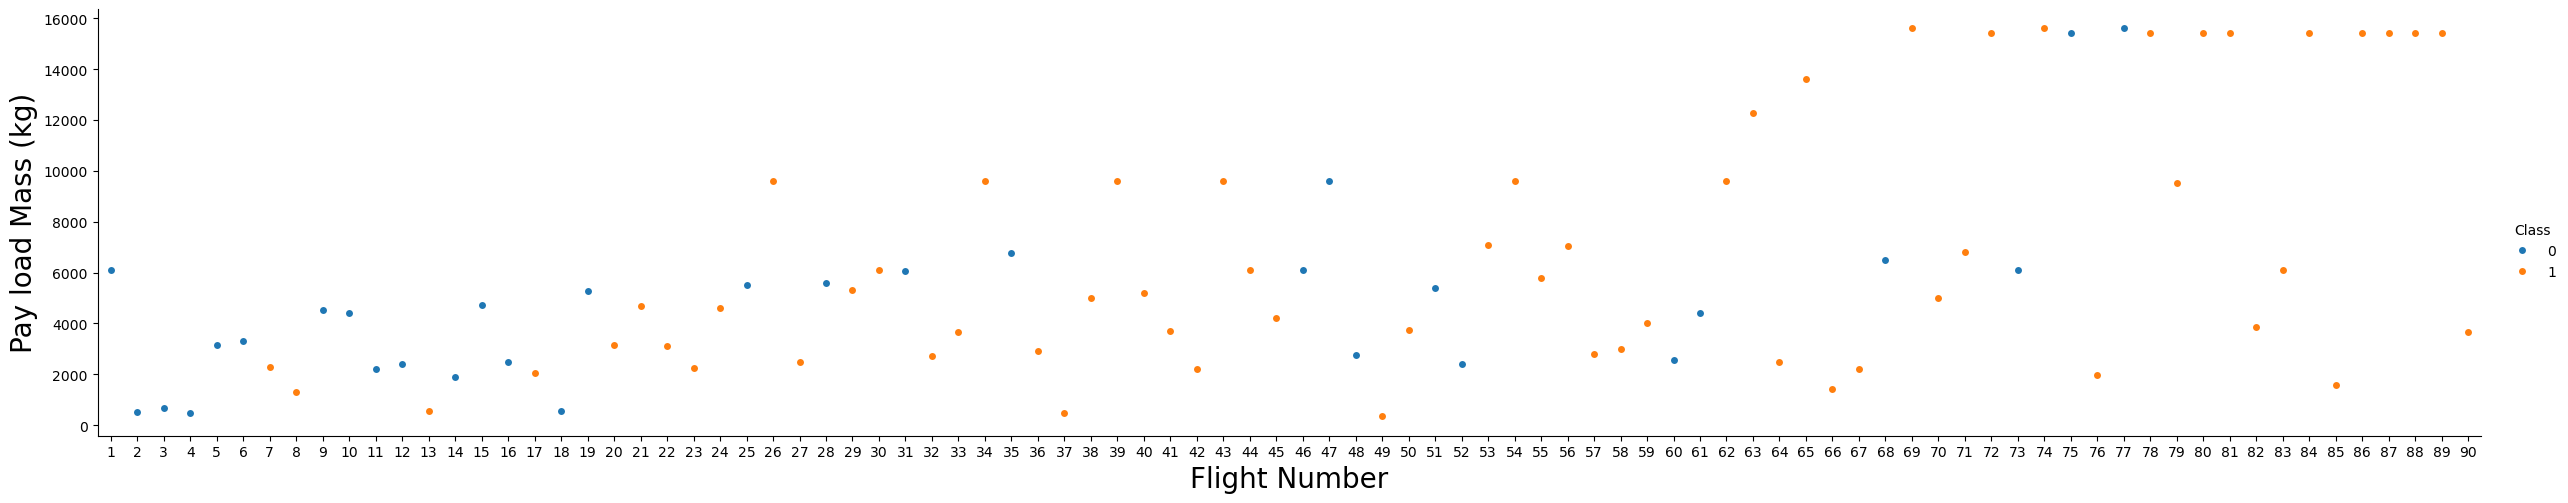

In [5]:
sns.catplot(y="PayloadMass", x="FlightNumber", hue="Class", data=df, aspect = 5)
plt.xlabel("Flight Number",fontsize=20)
plt.ylabel("Pay load Mass (kg)",fontsize=20)
plt.show()

Next, let's drill down to each site visualize its detailed launch records.


### TASK 1: Visualize the relationship between Flight Number and Launch Site


Use the function <code>catplot</code> to plot <code>FlightNumber</code> vs <code>LaunchSite</code>, set the  parameter <code>x</code>  parameter to <code>FlightNumber</code>,set the  <code>y</code> to <code>Launch Site</code> and set the parameter <code>hue</code> to <code>'class'</code>


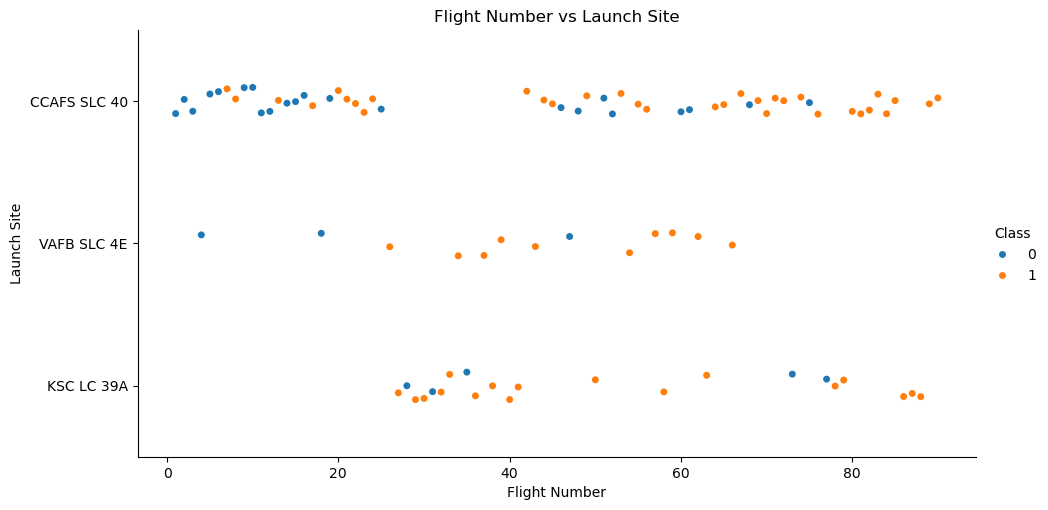

In [7]:
# Plot a scatter point chart with x axis to be Flight Number and y axis to be the launch site, and hue to be the class value

# TASK 1: Flight Number vs Launch Site

sns.catplot(
    y="LaunchSite",
    x="FlightNumber",
    hue="Class",
    data=df,
    kind="strip",
    height=5,
    aspect=2
)

plt.title("Flight Number vs Launch Site")
plt.xlabel("Flight Number")
plt.ylabel("Launch Site")
plt.show()

## Now try to explain the patterns you found in the Flight Number vs. Launch Site scatter point plots.

### Observations and Findings

The Flight Number vs. Launch Site scatter plot suggests the following patterns:
1. Landing success improves with flight experience: Earlier flights tend to have more unsuccessful landings (Class = 0), while later flights show more successful landings (Class = 1).
2. Launch sites have different success patterns: The distribution of successful and unsuccessful landings varies across launch sites.
3. Higher flight numbers show more successful landings: This suggests that SpaceX improved its landing technology and operational experience over time.
4. Launch site alone does not determine landing success: Both successful and unsuccessful landings can occur at the same launch site.
   
In Conclusion:
The scatter plot suggests that SpaceX's landing success rate generally improved as flight numbers increased. Earlier missions experienced more landing failures, while later missions achieved more successful landings. Although landing outcomes vary across launch sites, the overall pattern suggests that increasing flight experience contributed to improved landing performance.

### TASK 2: Visualize the relationship between Payload Mass and Launch Site


We also want to observe if there is any relationship between launch sites and their payload mass.


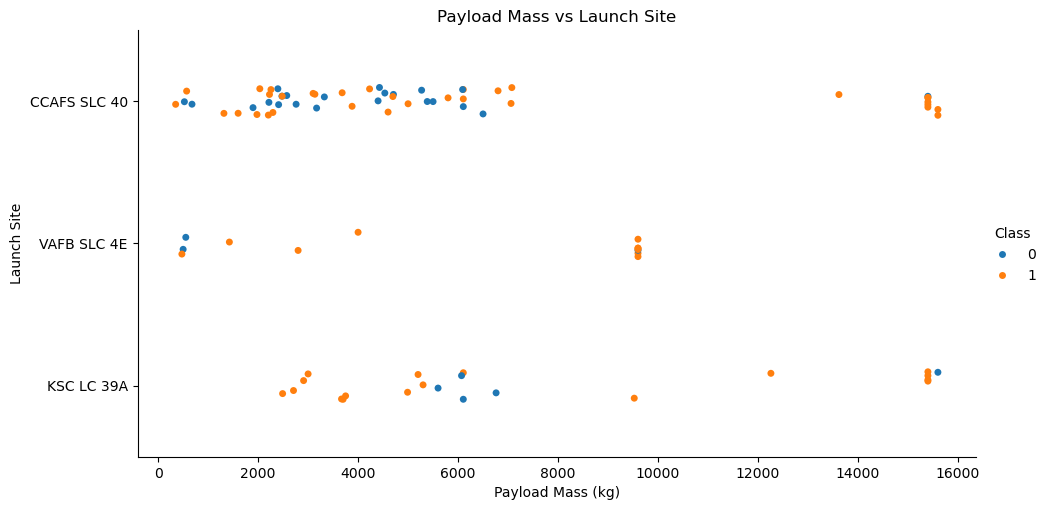

In [8]:
# Plot a scatter point chart with x axis to be Pay Load Mass (kg) and y axis to be the launch site, and hue to be the class value

# TASK 2: Payload Mass vs Launch Site

sns.catplot(
    y="LaunchSite",
    x="PayloadMass",
    hue="Class",
    data=df,
    kind="strip",
    height=5,
    aspect=2
)

plt.title("Payload Mass vs Launch Site")
plt.xlabel("Payload Mass (kg)")
plt.ylabel("Launch Site")
plt.show()

## Now if you observe Payload Mass Vs. Launch Site scatter point chart you will find for the VAFB-SLC  launchsite there are no  rockets  launched for  heavypayload mass(greater than 10000).

### Observations and findings

The plot helps us identify these patterns:

1. VAFB SLC-4E: No rockets carrying payloads greater than 10,000 kg were launched from this site in the dataset.
2. Payload distribution: Different launch sites handle different ranges of payload masses.
3. Landing outcomes: Successful and unsuccessful landings occur across different payload masses, suggesting that payload mass alone does not determine landing success.

Conclusion:
The Payload Mass vs. Launch Site scatter plot shows that payload mass distribution varies across SpaceX launch sites. In particular, VAFB SLC-4E has no recorded launches carrying payloads greater than 10,000 kg. Successful and unsuccessful landings occur across different payload masses, indicating that landing outcomes may depend on several factors beyond payload mass, including launch conditions and flight experience.

### TASK  3: Visualize the relationship between success rate of each orbit type


Next, we want to visually check if there are any relationship between success rate and orbit type.


Let's create a `bar chart` for the sucess rate of each orbit


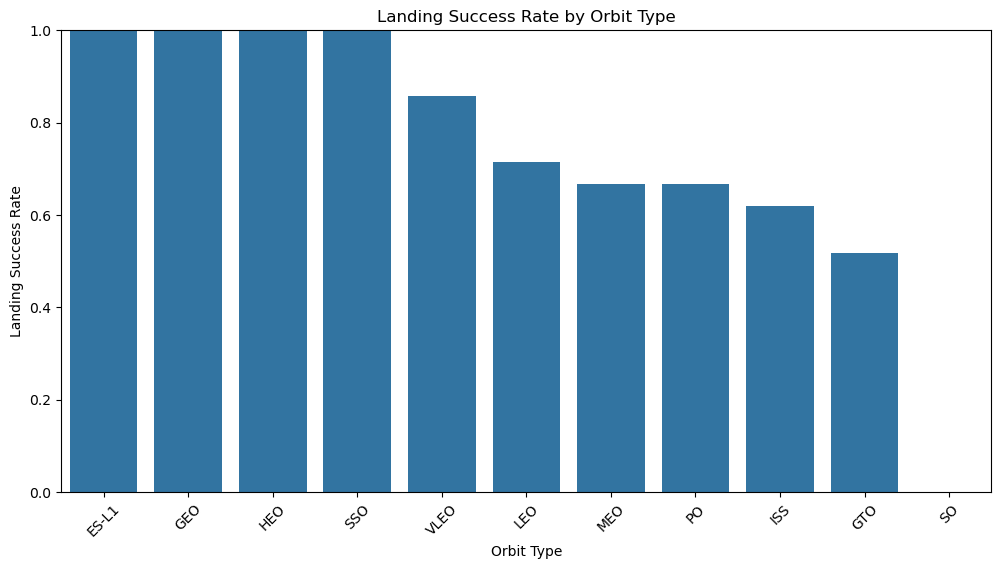

In [9]:
# HINT use groupby method on Orbit column and get the mean of Class column

orbit_success = (
    df.groupby("Orbit")["Class"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x="Orbit",
    y="Class",
    data=orbit_success
)

plt.title("Landing Success Rate by Orbit Type")
plt.xlabel("Orbit Type")
plt.ylabel("Landing Success Rate")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.show()

In [10]:
orbit_success["Success_Rate_Percent"] = (
    orbit_success["Class"] * 100
).round(2)

display(orbit_success[["Orbit", "Success_Rate_Percent"]])

,Orbit,Success_Rate_Percent
0,ES-L1,100.00
1,GEO,100.00
2,HEO,100.00
3,SSO,100.00
4,VLEO,85.71
5,LEO,71.43
6,MEO,66.67
7,PO,66.67
8,ISS,61.90
9,GTO,51.85


## Analyze the plotted bar chart to identify which orbits have the highest success rates.

The mean of Class gives the landing success rate because 1 represents a successful landing and 0 represents an unsuccessful landing.

### Analyzing the bar chart

Look for the tallest bars. These represent the orbit types with the highest landing success rates.
The chart also helps identify which orbit types have lower success rates. Remember that an orbit with only a few launches may have a high success rate without providing strong evidence of consistent performance.

### In conclusion:
After running the code, insert a Markdown cell below your graph:
The bar chart compares SpaceX's landing success rates across different orbit types. Orbit types with taller bars have higher recorded landing success rates, while shorter bars indicate lower success rates. This suggests that landing performance varies depending on the orbit type. However, the number of launches per orbit should also be considered when interpreting these results.

### TASK  4: Visualize the relationship between FlightNumber and Orbit type


For each orbit, we want to see if there is any relationship between FlightNumber and Orbit type.


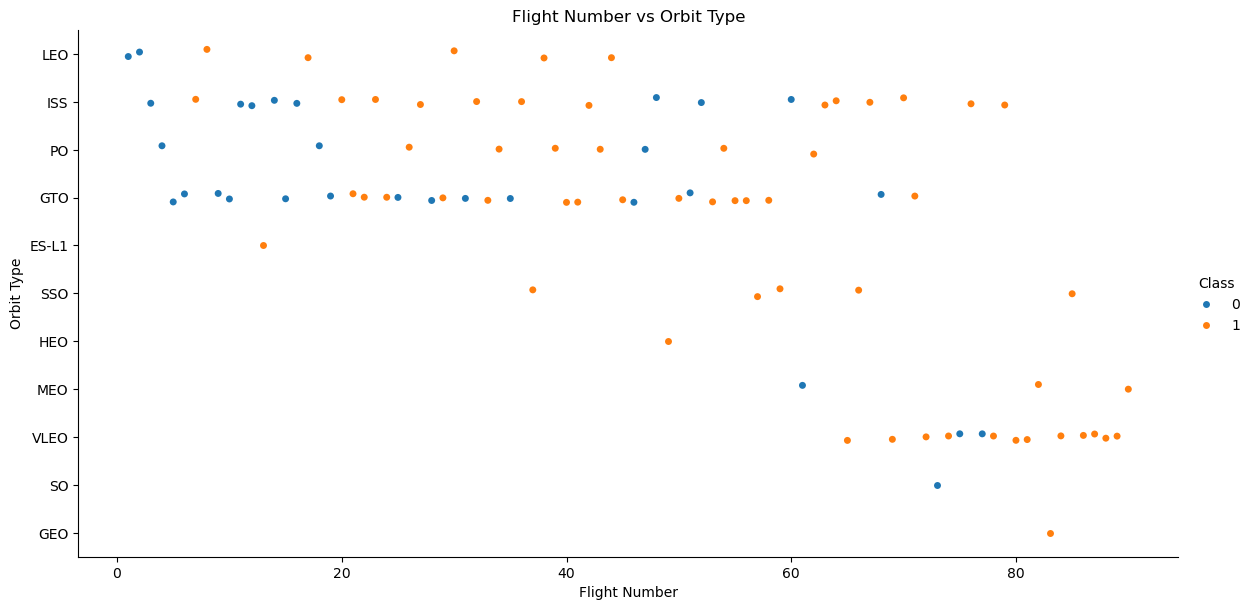

In [11]:
# Plot a scatter point chart with x axis to be FlightNumber and y axis to be the Orbit, and hue to be the class value

sns.catplot(
    x="FlightNumber",
    y="Orbit",
    hue="Class",
    data=df,
    kind="strip",
    height=6,
    aspect=2
)

plt.title("Flight Number vs Orbit Type")
plt.xlabel("Flight Number")
plt.ylabel("Orbit Type")
plt.show()

## You can observe that in the LEO orbit, success seems to be related to the number of flights. Conversely, in the GTO orbit, there appears to be no relationship between flight number and success.

### Observations and findings:

1. LEO (Low Earth Orbit): Landing success appears to improve as flight numbers increase, suggesting that SpaceX gained experience over time.
2. GTO (Geostationary Transfer Orbit): There is no clear relationship between flight number and landing success.
3. Other orbit types: Successful and unsuccessful landings may occur across different flight numbers.
4. Overall trend: Flight experience appears to be associated with improved landing success for some orbit types, but not necessarily all.

### In conclusion:
The Flight Number vs. Orbit Type scatter plot suggests that landing success varies across orbit types. For LEO missions, successful landings become more common as flight numbers increase, indicating possible improvements in SpaceX's landing technology and operational experience. However, GTO missions show no clear relationship between flight number and landing success. This suggests that the relationship between flight experience and landing performance may differ depending on the orbit type.

### TASK  5: Visualize the relationship between Payload Mass and Orbit type


Similarly, we can plot the Payload Mass vs. Orbit scatter point charts to reveal the relationship between Payload Mass and Orbit type


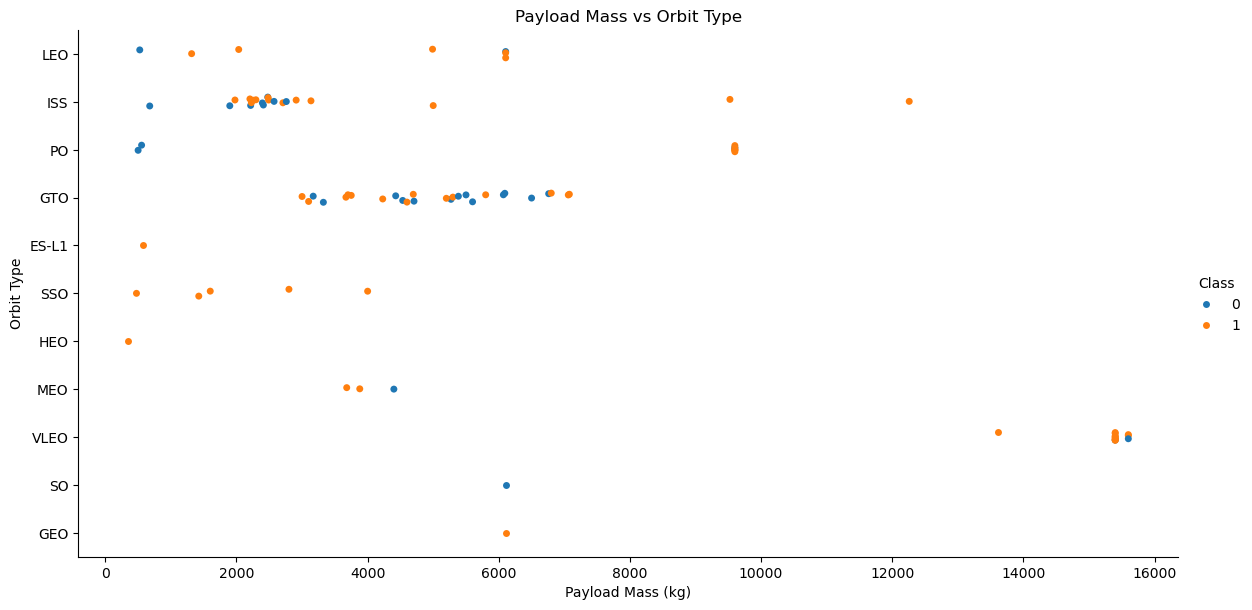

In [12]:
# Plot a scatter point chart with x axis to be Payload Mass and y axis to be the Orbit, and hue to be the class value

sns.catplot(
    x="PayloadMass",
    y="Orbit",
    hue="Class",
    data=df,
    kind="strip",
    height=6,
    aspect=2
)

plt.title("Payload Mass vs Orbit Type")
plt.xlabel("Payload Mass (kg)")
plt.ylabel("Orbit Type")
plt.show()

With heavy payloads the successful landing or positive landing rate are more for Polar,LEO and ISS.

However, for GTO, it's difficult to distinguish between successful and unsuccessful landings as both outcomes are present.

### Observations and findings

1. Polar orbit: Heavier payload missions appear to have more successful landings.
2. LEO (Low Earth Orbit): Successful landings are more common among heavier payload missions.
3. ISS (International Space Station): Heavier payload missions also show a higher proportion of successful landings.
4. GTO (Geostationary Transfer Orbit): Both successful and unsuccessful landings occur across different payload masses, making it difficult to identify a clear relationship.
These are visual observations, not proof that heavier payloads cause better landing outcomes.

In Conclusion:

The Payload Mass vs. Orbit Type scatter plot suggests that landing success varies depending on payload mass and orbit type. For Polar, LEO, and ISS missions, heavier payloads appear to be associated with more successful landings. However, GTO missions show a mixture of successful and unsuccessful landings across different payload masses, indicating no clear relationship. Overall, both payload mass and orbit type may influence landing outcomes, although further analysis is needed to establish their individual effects.

### TASK  6: Visualize the launch success yearly trend


You can plot a line chart with x axis to be <code>Year</code> and y axis to be average success rate, to get the average launch success trend.


The function will help you get the year from the date:


In [13]:
# A function to Extract years from the date 
year=[]
def Extract_year():
    for i in df["Date"]:
        year.append(i.split("-")[0])
    return year
Extract_year()
df['Date'] = year
df.head()
    

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


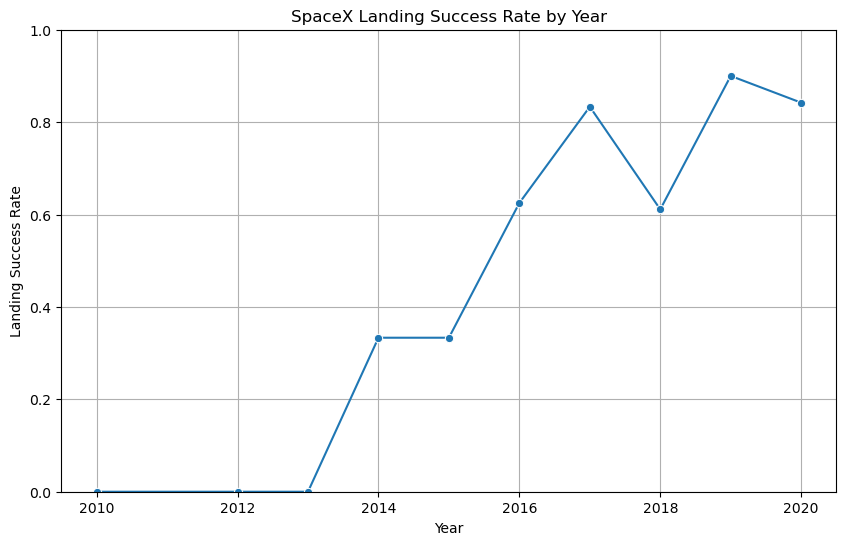

In [14]:
# Plot a line chart with x axis to be the extracted year and y axis to be the success rate

# TASK 6: Launch Success Yearly Trend

# Extract year from the Date column
df["Year"] = pd.to_datetime(
    df["Date"].astype(str).str[:4],
    format="%Y",
    errors="coerce"
).dt.year

# Calculate yearly landing success rate
yearly_success = (
    df.groupby("Year")["Class"]
    .mean()
    .reset_index()
)

# Plot the yearly success trend
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=yearly_success,
    x="Year",
    y="Class",
    marker="o"
)

plt.title("SpaceX Landing Success Rate by Year")
plt.xlabel("Year")
plt.ylabel("Landing Success Rate")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

In [15]:
yearly_success["Success_Rate_Percent"] = (
    yearly_success["Class"] * 100
).round(2)

display(yearly_success)

,Year,Class,Success_Rate_Percent
0,2010,0.000000,0.00
1,2012,0.000000,0.00
2,2013,0.000000,0.00
3,2014,0.333333,33.33
4,2015,0.333333,33.33
5,2016,0.625000,62.50
6,2017,0.833333,83.33
7,2018,0.611111,61.11
8,2019,0.900000,90.00
9,2020,0.842105,84.21


## you can observe that the sucess rate since 2013 kept increasing till 2020

### Observations and findings
The line chart helps us examine whether SpaceX's landing success rate improved over time.
The expected general pattern is an upward trend, with lower success rates in the early years and higher rates in later years.

Conclusion:
The yearly landing success rate chart illustrates how SpaceX's booster landing performance changed over time. The overall trend is expected to show improvement as SpaceX gained experience and developed more reliable landing technology. This suggests that technological advancements and operational experience contributed to increased landing success rates.

## Features Engineering


By now, you should obtain some preliminary insights about how each important variable would affect the success rate, we will select the features that will be used in success prediction in the future module.


In [16]:
features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]
features.head()

,FlightNumber,PayloadMass,Orbit,LaunchSite,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial
0,1,6104.959412,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0003
1,2,525.000000,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0005
2,3,677.000000,ISS,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0007
3,4,500.000000,PO,VAFB SLC 4E,1,False,False,False,NaN,1.0,0,B1003
4,5,3170.000000,GTO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B1004


### TASK  7: Create dummy variables to categorical columns


Use the function <code>get_dummies</code> and <code>features</code> dataframe to apply OneHotEncoder to the column <code>Orbits</code>, <code>LaunchSite</code>, <code>LandingPad</code>, and <code>Serial</code>. Assign the value to the variable <code>features_one_hot</code>, display the results using the method head. Your result dataframe must include all features including the encoded ones.


In [17]:
# HINT: Use get_dummies() function on the categorical columns

features = df[
    [
        "FlightNumber",
        "PayloadMass",
        "Orbit",
        "LaunchSite",
        "Flights",
        "GridFins",
        "Reused",
        "Legs",
        "LandingPad",
        "Block",
        "ReusedCount",
        "Serial"
    ]
].copy()

display(features.head())

,FlightNumber,PayloadMass,Orbit,LaunchSite,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial
0,1,6104.959412,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0003
1,2,525.000000,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0005
2,3,677.000000,ISS,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0007
3,4,500.000000,PO,VAFB SLC 4E,1,False,False,False,NaN,1.0,0,B1003
4,5,3170.000000,GTO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B1004


In [18]:
# One-Hot Encoding

features_one_hot = pd.get_dummies(
    features,
    columns=["Orbit", "LaunchSite", "LandingPad", "Serial"]
)

display(features_one_hot.head())

,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1,6104.959412,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
1,2,525.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
2,3,677.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
3,4,500.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
4,5,3170.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False


In [19]:
print("Original features shape:", features.shape)
print("Encoded features shape:", features_one_hot.shape)

print("\nMissing values:")
print(features_one_hot.isnull().sum().sum())

Original features shape: (90, 12)
Encoded features shape: (90, 80)

Missing values:
0


### TASK  8: Cast all numeric columns to `float64`


Now that our <code>features_one_hot</code> dataframe only contains numbers, cast the entire dataframe to variable type <code>float64</code>


In [20]:
# HINT: use astype function

features_one_hot = features_one_hot.astype("float64")

print(features_one_hot.dtypes)

FlightNumber    float64
PayloadMass     float64
Flights         float64
GridFins        float64
Reused          float64
                 ...   
Serial_B1056    float64
Serial_B1058    float64
Serial_B1059    float64
Serial_B1060    float64
Serial_B1062    float64
Length: 80, dtype: object


In [21]:
print("Dataset shape:", features_one_hot.shape)

print(
    "All columns are float64:",
    (features_one_hot.dtypes == "float64").all()
)

Dataset shape: (90, 80)
All columns are float64: True


In [22]:
features_one_hot.to_csv("dataset_part_3.csv", index=False)

print("dataset_part_3.csv exported successfully!")

dataset_part_3.csv exported successfully!


We can now export it to a <b>CSV</b> for the next section,but to make the answers consistent, in the next lab we will provide data in a pre-selected date range.


<code>features_one_hot.to_csv('dataset_part\_3.csv', index=False)</code>


## Authors


[Pratiksha Verma](https://www.linkedin.com/in/pratiksha-verma-6487561b1/)


<!--## Change Log-->


<!--
| Date (YYYY-MM-DD) | Version | Changed By      | Change Description      |
| ----------------- | ------- | -------------   | ----------------------- |
| 2022-11-09        | 1.0     | Pratiksha Verma | Converted initial version to Jupyterlite|
| 2024-07-18        | 1.2     | Anita Verma | Clarified instructions|
-->


### <h3 align="center"> IBM Corporation 2022. All rights reserved. <h3/>
